<a href="https://colab.research.google.com/github/sudeepbhattad02-creator/AIProject2/blob/main/Full_Code_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200"/>
</p></center>

<center><font size=10>Artificial Intelligence and Machine Learning</center></font>
<center><font size=6>Deploying GenAI solutions</center></font>

<center><p float="center">
  <img src="https://images.pexels.com/photos/28238364/pexels-photo-28238364.jpeg" alt="hotel-qna" width="640"/>
</p></center>
<center><font size=6>AuroraStays QnA</center></font>

# Problem Statement

## Business Context

**AuroraStay Hotels** is a mid-sized hotel group operating **18 business and leisure properties** across major cities in the USA, adding **3 to 4 new properties every year**.

Hotel staff handle around **1,200 guest queries per week** about:

- Room types
- Check-in/check-out
- Cancellation policies
- Refunds
- Breakfast
- Parking
- Pets
- Amenities
- Additional charges

Simple queries can be answered using existing FAQs. However, around **40% of queries are complex** and require information from multiple documents, such as:

- Booking terms
- Cancellation policies
- Room information
- Guest guidelines

Manually combining this information takes **8 to 12 minutes per query** and results in a **15% to 20% error rate** because answers may be incomplete or incorrect.

As the hotel group grows, the number of properties and property-specific policies also increases. With **45% annual staff turnover**, institutional knowledge is constantly lost.

## Key Risks

- **Faithfulness:** Avoid unsupported information.
- **Retrieval Completeness:** Retrieve all relevant information required to answer the query.
- **Retrieval Precision:** Retrieve relevant source chunks while minimizing irrelevant information.
- **Answer Relevancy:** Directly answer the guest's question.

A **RAG system** can retrieve relevant information from these documents and help staff provide **accurate, source-grounded answers**.

## Objective

The objective is to build a **POC for a user interface** for AuroraStay Hotels where hotel staff can enter natural-language questions and receive answers based on the hotel's documents.

The application should:

- Provide a simple UI where staff can enter their questions.
- Retrieve the most relevant information from the hotel's document collection.
- Generate an answer grounded **only in the retrieved information**.
- Display the supporting source information along with the answer.
- **Reduce the number of queries that require manual lookup or escalation**, rather than focusing on reducing the time spent handling each query.

Since this is a **POC**, the application will initially be **internal-facing**, allowing the hotel team to test it extensively, ensure that user queries are answered consistently, and validate the **accuracy and reliability** of the system before deploying it for broader use.

> **Note:** The objective at this stage is **not to reduce query-handling time**. The primary objective is to determine whether the system can reliably answer a meaningful proportion of queries without requiring manual effort.

## Success Criteria

| **Business Objective** | **Technical Metric** | **Threshold** |
|---|---|---:|
| Avoid unsupported information | Faithfulness | >= 0.85 |
| Retrieve all relevant information | Contextual Recall | >= 0.80 |
| Retrieve relevant chunks | Contextual Precision | >= 0.75 |
| Answer the question asked | Answer Relevancy | >= 0.75 |
| Reduce the number of queries requiring manual searches for policy information | Queries Confidently Answered | >= 50% |

**Composite Score = 0.35 × Faithfulness + 0.25 × Contextual Recall + 0.20 × Contextual Precision + 0.20 × Answer Relevancy**

The weights for the composite score are **informed by past evaluation results and the relative importance of each metric to the business objectives**. Faithfulness is given the highest weight because avoiding unsupported or misleading information is the most critical requirement in this use case.

The pipeline routes every generated answer through a **scoring stage**. Based on the composite score, the answer is routed to one of two actions:

1. **Auto Answer (score >= 75%)**  
   The generated answer and its supporting source chunks are considered reliable enough to present directly to the representative for immediate use with the customer.

2. **Manual Lookup (score < 75%)**  
   The system output is not considered reliable enough to act on. The representative falls back to the existing process by looking up the answer manually or escalating it to the back-office helpdesk.

## Data Description

**Policy Documents**

| Document | Pages | Description |
| :- | :-: | :- |
| `aurorastay_booking_terms_and_cancellation_policy.pdf` | 5 | Covers individual transient reservation terms including flexible, Advance Purchase, member/promotional, and group rate plan rules, cancellation deadlines, no-show charges, modification procedures, taxes and deposit handling, and a six-property quick-reference matrix |
| `aurorastay_room_and_property_information.pdf` | 5 | Details room types and occupancy limits (King, Double Queen, Accessible King, Suite), check-in/check-out times, early arrival and late departure handling, guest amenities (breakfast, Wi-Fi, fitness, luggage storage, cribs), parking and pet policies, service animal procedures, and accessibility request guidelines |
| `aurorastay_refunds_and_additional_charges_guide.pdf` | 4 | Outlines refund eligibility for flexible, Advance Purchase, duplicate, and service-recovery scenarios, itemized additional charges (parking, pet fees, late checkout, smoking remediation, damage, lost key), incidentals authorization and release procedures, and the five-step refund dispute workflow |
| `aurorastay_guest_conduct_accessibility_and_resolution_guidelines.pdf` | 5 | Defines guest conduct rules (quiet hours, smoking, threats, illegal activity, visitors), ADA accessibility and service animal handling, safety and privacy protocols, the five-stage complaint resolution process, and the escalation matrix for danger, discrimination, privacy, charge disputes, and legal or media requests |

**Evaluation and Test Data Files**

| File | Queries | Description |
| :- | :-: | :- |
| `evaluation.csv` | 10 | Benchmark evaluation queries with expected answers and relevant policy contexts spanning check-in times, cancellation rules, pet fees, smoking charges, service animals, refunds, and accessibility procedures |
| `test.xlsx` | 10 | Test queries containing questions, expected answers, and relevant contexts used for pipeline evaluation across booking, property information, conduct, and refund policy scenarios |

# **Please read the instructions carefully before starting the project.**

## Instructions

This is a full Python code notebook in which the instructions and tasks to be performed are mentioned throughout the notebook.

* A few code snippets have blanks `_____` that need to be filled appropriately. A comment is provided next to each blank explaining what needs to be filled in the blank space.

* In other sections, the code cell is intentionally left blank. Guidelines are provided above the code cell explaining what needs to be done. Read and follow these guidelines carefully before writing the required code.

* Hence, read the guidelines provided throughout the notebook carefully before proceeding with each task.

* For code snippets with blanks, refer to the comments next to the blanks to understand what needs to be filled in.

* Identify the task to be performed correctly, and only then proceed to fill in the blanks or write the required code.

# Installing and Importing the Necessary Libraries

In [1]:
# Install all required packages using uv pip for fast dependency resolution
!uv pip install docling==2.126.0 pandas==2.2.3 transformers==5.16.1 langchain-huggingface==1.2.2 langchain-text-splitters==1.1.2 langchain-community==0.4.2 faiss-cpu==1.15.0 langchain-openai==1.6.1 deepeval==4.2.2 PyGithub==2.6.1 -q

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [1]:
# Import function for displaying outputs in Jupyter/Google Colab
from IPython.display import display

# Import library for working with tabular data
import pandas as pd

# To supress warnings
import warnings

# To make API requests
import requests

# Import Docling's document converter for processing PDF documents
from docling.document_converter import DocumentConverter

# Import tokenizer for determining token counts and preparing text for chunking
from transformers import AutoTokenizer

# Import LangChain's recursive character text splitter for token-aware chunking
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Import library for working with JSON data and OS related functionalities
import json,os

# Import LangChain's Document class for representing text and metadata
from langchain_core.documents import Document as LCDocument

# Import Hugging Face embedding model integration for creating vector embeddings
from langchain_huggingface import HuggingFaceEmbeddings

# Import OpenAI-compatible chat model for generating RAG responses
from langchain_openai import ChatOpenAI

# Import FAISS vector database for storing and retrieving document embeddings
from langchain_community.vectorstores import FAISS

# Import DeepEval evaluation framework
from deepeval import evaluate

# Import DeepEval test case class for defining evaluation inputs and outputs
from deepeval.test_case import LLMTestCase

# Import DeepEval metrics for evaluating different aspects of the RAG system

from deepeval.test_case import SingleTurnParams
from deepeval.metrics import GEval

# Import OpenAI model wrapper used as the evaluation/judge model in DeepEval
from deepeval.models import OpenAIModel

# Import Python's operating system interface for managing environment variables
import os

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)
warnings.filterwarnings("ignore", category=DeprecationWarning)

/tmp/ipykernel_3913/2128305974.py:35: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


All the key libraries are imported here. The main components are:

- **Docling** for parsing PDF documents into structured markdown.
- **LangChain** modules for text splitting, embeddings, vector storage, and LLM interaction.
- **DeepEval** for evaluating the quality of the RAG pipeline using LLM-as-a-Judge metrics.
- **Pandas display options** are set to show full row/column content without truncation, which helps when inspecting long text chunks.
- **DeprecationWarnings** are suppressed to keep the notebook output clean.

# Data Understanding

## Loading the documents

- We define the file paths to the four hotel policy PDF documents that form the knowledge base for this RAG system.
- Each document covers a different area of hotel operations.

In [2]:
# Create the root folder

root_path = 'Data'

os.makedirs(root_path, exist_ok=True)

**Note:** After executing the previous cell, a folder named **Data** will be created. Ensure that all the PDF files are uploaded to this folder before executing the code cell below.

In [6]:
# List all policy document PDF file paths

pdf_paths = [
    root_path + "/" + "aurorastay_room_and_property_information.pdf",
    root_path + "/" + "aurorastay_refunds_and_additional_charges_guide.pdf",
    root_path + "/" + "aurorastay_guest_conduct_accessibility_and_resolution_guidelines.pdf",
    root_path + "/" + "aurorastay_booking_terms_and_cancellation_policy.pdf"
]

Four policy documents are loaded:

1. **Room and property information** covering room types, amenities, and property-specific details.
2. **Refunds and additional charges** explaining fee structures and refund eligibility.
3. **Guest conduct, accessibility, and resolution guidelines** for behavioral policies and dispute handling.
4. **Booking terms and cancellation policy** with reservation rules and cancellation windows.

Together, these documents should cover the majority of questions hotel staff receive from guests.

- The `DocumentConverter` from Docling handles PDF parsing.
- It extracts text, tables, and document structure from PDFs and converts them into a format that preserves headings, lists, and table layouts.
  - This is important because hotel policy documents often contain structured tables (e.g., room rate grids, fee schedules) that would be lost with a simple text extractor.

In [7]:
# Initialize the Docling document converter
converter = DocumentConverter()

- Each PDF is converted one at a time and stored in a dictionary keyed by its file path.
- The converter processes the document layout, extracts text and tables, and returns a Docling document object.
- The print statement after each file confirms that the conversion completed successfully.
  - This step can take a minute or so depending on the size and complexity of the PDFs.

**Note:** The code snippet below may take 10 to 15 minutes to complete its execution.

In [8]:
# Convert each policy PDF into a Docling document object
docs = {}
for path in pdf_paths:
    result = converter.convert(path)
    docs[path] = result.document
    print(path," Completed ",end='\n')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

Data/aurorastay_room_and_property_information.pdf  Completed 
Data/aurorastay_refunds_and_additional_charges_guide.pdf  Completed 
Data/aurorastay_guest_conduct_accessibility_and_resolution_guidelines.pdf  Completed 
Data/aurorastay_booking_terms_and_cancellation_policy.pdf  Completed 


## Viewing the documents

### Viewing the markdown

In [9]:
# Select one document to preview its converted markdown output
path = root_path + "/" + "aurorastay_refunds_and_additional_charges_guide.pdf"

In [10]:
# Display the converted document as markdown to inspect its preserved structure
print(docs[path].export_to_markdown())

## Refunds and Additional Charges Guide

Refund eligibility, authorization holds, itemized charges, and dispute workflows

| Policy code    | AS-03                                                                                                                                 |
|----------------|---------------------------------------------------------------------------------------------------------------------------------------|
| Effective date | January 1, 2026                                                                                                                       |
| Review date    | January 1, 2027, or sooner if law, systems, or operating conditions change                                                            |
| Owner          | Guest Experience and Property Operations                                                                                              |
| Applies to     | AuroraStay managed and franchised properties in the United States, unless a signed 

- The markdown export shows how Docling preserved the original document structure.
- Headings, subheadings, bullet points, and tables are all retained in markdown format.
- This is the text that will later be split into chunks for the vector database, so having clean, well-structured markdown directly improves retrieval quality.

### Viewing the tables

Let us also take a look at the tables extracted from the documents. Tables are particularly important in hotel policy documents because they often contain structured data like fee schedules, room configurations, and property-specific details.

In [11]:
# Extract and display all tables from the converted documents
for path, doc in docs.items():
    for item, _ in doc.iterate_items():
        if getattr(item, "label", "") == "table":
            print(f"\n--- Table from: {path} ---")
            print(item.export_to_markdown(doc=doc))


--- Table from: Data/aurorastay_room_and_property_information.pdf ---
| Policy code    | AS-02                                                                                                                                 |
|----------------|---------------------------------------------------------------------------------------------------------------------------------------|
| Effective date | January 1, 2026                                                                                                                       |
| Review date    | January 1, 2027, or sooner if law, systems, or operating conditions change                                                            |
| Owner          | Guest Experience and Property Operations                                                                                              |
| Applies to     | AuroraStay managed and franchised properties in the United States, unless a signed contract or local rule requires a different result |

- The loop iterates through every item in each document and filters for items labeled as "table."
- Each table is exported as markdown, preserving its row/column structure.
- This confirms that Docling successfully extracted tabular data from the PDFs, which is essential since many guest queries involve looking up specific values from these tables.

# Retrieval Augmented Generation System

## Chunking

### Choosing the embedding model

Here, the embedding model chosen is **"HarishMaths/Hotel-Policy-Embedding"**, which is fine-tuned on hotel policy documents. Hence, it is expected to provide better retrieval quality compared to other base models.

In [12]:
# define the model name
EMBED_MODEL = "HarishMaths/Hotel-Policy-Embedding"

# Load the domain-specific embedding model tokenizer and check its maximum token limit
tokenizer = AutoTokenizer.from_pretrained(EMBED_MODEL)

print(f"Model max tokens: {tokenizer.model_max_length}")

Model max tokens: 128


- The model's maximum token length tells us the upper bound on how much text can be encoded into a single embedding vector.
-  This limit directly affects how we configure the chunking strategy in the next step.
- Chunks that exceed this limit would be silently truncated, potentially losing important information.

Before chunking, it helps to see how the tokenizer actually breaks text into tokens. This gives us a sense of the token-to-word ratio for hotel policy language.

In [13]:
# Replace the "_____" with an actual query to test
sample = "what are the cancellation charges if we cancle with in 24 hours?"


tokens = tokenizer.tokenize(sample)
print(f"Sample: '{sample}'")
print(f"Tokens ({len(tokens)}): {tokens}")

Sample: 'what are the cancellation charges if we cancle with in 24 hours?'
Tokens (14): ['what', 'are', 'the', 'cancellation', 'charges', 'if', 'we', 'can', '##cle', 'with', 'in', '24', 'hours', '?']


- The sample sentence produces a specific number of tokens, and we can see how individual words get split into subwords.
- Knowing this ratio helps us reason about chunk sizes.
  - For example, a 512-token chunk will typically hold roughly 350 to 400 words of hotel policy text, which is enough to capture a complete policy section in most cases.

### Define the chunker

**Guidelines**

- Define a text splitter of your choice.
- The text splitter **must be assigned to the variable `splitter`**, as this variable is used in the code that follows.

The `RecursiveCharacterTextSplitter` is initialized with the same tokenizer used by the embedding model. This ensures that chunk sizes are measured in the same token units the model expects.

Key configuration choices:
- **chunk_size=512**: Each chunk can hold up to 512 tokens, staying within the embedding model's limit.
- **chunk_overlap=50**: Adjacent chunks share 50 tokens of overlap, which helps preserve context at chunk boundaries.
- **separators**: The splitter tries to break text at paragraph boundaries first (`\n\n`), then line breaks, then markdown headings (`##`), then sentences, then words, and finally characters as a last resort. This hierarchy keeps semantically related content together as much as possible.

In [14]:
# Initialize the RecursiveCharacterTextSplitter using the same tokenizer as the embedding model
splitter = RecursiveCharacterTextSplitter.from_huggingface_tokenizer(
    tokenizer=tokenizer,                  # Tokenizer used by the embedding model
    chunk_size=512,                      # Maximum number of tokens per chunk
    chunk_overlap=50,                    # Number of overlapping tokens
    separators=["\n\n", "\n", "##", ". ", " ", ""]
)

### Chunking the documents

In [15]:
# Wrap each document's Markdown export as a single LangChain Document, then
# split it into chunks using the RecursiveCharacterTextSplitter
raw_docs = [
    LCDocument(page_content=doc.export_to_markdown(), metadata={"source": path})
    for path, doc in docs.items()
]

lc_docs = splitter.split_documents(raw_docs)

print(f"Total chunks: {len(lc_docs)}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (232 > 128). Running this sequence through the model will result in indexing errors


Total chunks: 37


- Each document's markdown export is first wrapped into a single LangChain `Document` object with its source path as metadata. Then the splitter breaks these into smaller chunks.
- The total chunk count tells us how many vectors we will store in the database. Each chunk retains the `source` metadata so we can trace any retrieved chunk back to its original document.

Let us preview the first 400 characters of each chunk to verify the split looks reasonable.

In [16]:
# Preview the text content of each generated chunk
for i, chunk in enumerate(lc_docs):
    print(f"\n--- Chunk {i} | {chunk.metadata['source']} ---")
    print(chunk.page_content[:400])
    print("..." if len(chunk.page_content) > 1000 else "")


--- Chunk 0 | Data/aurorastay_room_and_property_information.pdf ---
## Room and Property Information Guide

Room types, arrival and departure, amenities, parking, breakfast, pets, and accessibility

| Policy code    | AS-02                                                                                                                                 |
|----------------|------------------------------------------------------------------------------------------------
...

--- Chunk 1 | Data/aurorastay_room_and_property_information.pdf ---
Operating note: This is a business policy for guest service teams. It is not a substitute for a property license, emergency procedure, signed group agreement, or advice from qualified counsel. Local and state requirements can be more protective than this baseline.

## 1. Room types and occupancy

Room names describe the bed configuration and major features shown on the property page. They do not g
...

--- Chunk 2 | Data/aurorastay_room_and_property_inf

- Scanning through the chunk previews, we can check whether the splits are happening at logical boundaries.
- Good chunks should start and end at natural breakpoints like section headings or paragraph boundaries, rather than cutting sentences in half.
- The overlap between consecutive chunks should also be visible.

Let us also verify the metadata attached to each chunk.

In [17]:
# Preview the metadata of each generated chunk
for i, chunk in enumerate(lc_docs):
    print(f"\n--- Chunk {i} ---")
    print(chunk.metadata)


--- Chunk 0 ---
{'source': 'Data/aurorastay_room_and_property_information.pdf'}

--- Chunk 1 ---
{'source': 'Data/aurorastay_room_and_property_information.pdf'}

--- Chunk 2 ---
{'source': 'Data/aurorastay_room_and_property_information.pdf'}

--- Chunk 3 ---
{'source': 'Data/aurorastay_room_and_property_information.pdf'}

--- Chunk 4 ---
{'source': 'Data/aurorastay_room_and_property_information.pdf'}

--- Chunk 5 ---
{'source': 'Data/aurorastay_room_and_property_information.pdf'}

--- Chunk 6 ---
{'source': 'Data/aurorastay_room_and_property_information.pdf'}

--- Chunk 7 ---
{'source': 'Data/aurorastay_room_and_property_information.pdf'}

--- Chunk 8 ---
{'source': 'Data/aurorastay_room_and_property_information.pdf'}

--- Chunk 9 ---
{'source': 'Data/aurorastay_refunds_and_additional_charges_guide.pdf'}

--- Chunk 10 ---
{'source': 'Data/aurorastay_refunds_and_additional_charges_guide.pdf'}

--- Chunk 11 ---
{'source': 'Data/aurorastay_refunds_and_additional_charges_guide.pdf'}

--- 

- Each chunk carries a `source` field pointing to the PDF it came from.
- This metadata is preserved through the vector store and will be returned alongside retrieved chunks during inference, allowing us to cite the source document in the final answer.

## Vector Database

### Loading the embedding model

In [18]:
# Load the embedding model
embeddings = HuggingFaceEmbeddings(
    model_name=EMBED_MODEL,  # Pre-trained embedding model
    model_kwargs={"device": "cpu"},                  # Run the model on CPU
    encode_kwargs={"normalize_embeddings": True},   # Normalize embeddings for similarity search
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

- The embedding model is loaded onto the CPU and configured to normalize its output vectors.
- Normalization ensures that cosine similarity and inner product give the same ranking, which makes the similarity search in FAISS more consistent.
- Since this is a domain-specific model fine-tuned on hotel policy data, it should produce better embeddings for this use case compared to a general-purpose model.

### Creating the Vector Database

**Guidelines**

- Create a vector store using the processed LangChain documents stored in `lc_docs`.
- Use the **same embedding model** that was selected earlier for this RAG application.
- Keep the variable name `vectorstore` unchanged, as it is used in the code that follows.

In [19]:
# Create a FAISS vector store from the LangChain documents
vectorstore = FAISS.from_documents(
    documents=lc_docs,
    embedding=embeddings,
)
print(f"Vectors stored: {vectorstore.index.ntotal}")

Vectors stored: 37


### Retrieval System

The retrieval function wraps FAISS similarity search into a clean interface. Given a query string, it returns the top-k most similar chunks along with their metadata.

In [20]:
# Retrieve the top-k relevant chunks from the vector store
def retrieve(query: str, k: int = 2,vectorstore=None) -> list[str]:
    results = vectorstore.similarity_search(query, k=k)

    # Return each chunk with its content and metadata
    return [
        f"Content:\n{r.page_content}\n\nMetadata:\n{r.metadata}"
        for r in results
    ]

- The `retrieve` function performs a similarity search on the vector store and returns formatted strings containing both the chunk content and its metadata.
- Formatting them this way makes it easy to pass the results directly into the LLM prompt later.
- The `k` parameter controls how many chunks are retrieved, defaulting to 2.

Let us test the retrieval system with a sample query about pet charges at a specific property.

In [21]:
# Replace the blank with an actual query to test

query = "what are the cancellation charges if I cancel within 24 hours?"


for i, chunk in enumerate(retrieve(query,vectorstore=vectorstore)):
    print(f"\n--- Result {i} ---")
    print(chunk)


--- Result 0 ---
Content:
Operating note: This is a business policy for guest service teams. It is not a substitute for a property license, emergency procedure, signed group agreement, or advice from qualified counsel. Local and state requirements can be more protective than this baseline.

## 1. Room types and occupancy

Room names describe the bed configuration and major features shown on the property page. They do not guarantee a specific floor, view, connecting room, or accessible feature unless the reservation confirmation or a documented request states it. The property may assign an equivalent room when the reserved room type is unavailable, subject to manager review.

| Room type       | Typical configuration                          | Typical occupancy                                                | Important note                                                                            |
|-----------------|------------------------------------------------|-------------------

- The retrieved chunks contain information about cancellation policies and charges.  
- Looking at the results, we can verify whether the retrieval system is pulling in the right sections from the knowledge base.
- Chunks are relevant to the query, it means the embedding model and vector store are working together correctly.

## Generation System

### Loading the LLM

We load the OpenAI API credentials from `config.json` for use with the LLM and embedding model.

**Note**: Before executing the below code snippet, ensure that `config.json` is uploaded.

In [23]:
# Load API configuration from the JSON config file
with open(root_path + "/config.json", "r") as f:
    config = json.load(f)

# Set environment variables for OpenAI API access
os.environ["OPENAI_API_KEY"] = config["OPENAI_API_KEY"]
os.environ["OPENAI_API_BASE"] = config["OPENAI_API_BASE"]

print("Configuration loaded.")

Configuration loaded.


- The API key and base URL are loaded from a local `config.json` file and set as environment variables.
- This approach keeps sensitive credentials out of the notebook code.
- The same environment variables will also be picked up by LangChain's ChatOpenAI wrapper automatically.

**Guidelines**

- Define the LLM model name and assign it to `MODEL`.
- Set `TEMPERATURE` to a low value, such as `0` to `0.2`, for more consistent responses.
- Set `TOP_P` to a value around `0.9` to `1`.
- Set `MAX_TOKENS` based on the expected length of the response. A range of **256 to 512** is a good starting point for hotel policy questions.
- Initialize `ChatOpenAI` using these four parameters.
- Use the `OPENAI_API_KEY` and `OPENAI_API_BASE` values provided in `config` to connect to the LLM.

In [24]:
# Define the model configuration
MODEL = "gpt-4o-mini"
TEMPERATURE = 0
TOP_P = 1
MAX_TOKENS = 512

# Initialize the LLM with the defined configuration
llm = ChatOpenAI(
    model=MODEL,                              # Specify the LLM model
    temperature=TEMPERATURE,                  # Control randomness
    top_p=TOP_P,                              # Control the diversity of token selection
    max_tokens=MAX_TOKENS,                    # Set the maximum response length
    openai_api_key=config["OPENAI_API_KEY"],  # Provide the API key
    openai_api_base=config["OPENAI_API_BASE"] # Specify the API endpoint
)

In [25]:
# Replace the '_____' to an actual query to test
TEST_QUERY_LLM = "Say 'The LLM is ready to use' and nothing else."

# Send the test query to the LLM
response = llm.invoke(TEST_QUERY_LLM)

# Display the LLM response
print(response.content)

The LLM is ready to use.


- A quick connectivity check to make sure the LLM is reachable and responding.
- The Output says "The LLM is ready to use " which confirms that the API key, base URL, and model name are all configured correctly.

### Defining the generation system

**Guidelines**

- Define your own `rules` to guide how the LLM should answer hotel policy questions.
- Your rules should explain **how the retrieved information should be used** and **how the final answer should be written**.
- Consider instructions such as using only the retrieved information, avoiding assumptions, including relevant conditions or exceptions, and clearly handling cases where the information is insufficient.
- You can write multiple rules based on what you want the RAG application to do.
- Experiment with different rules and observe how they affect the generated answers.

The generation function builds a structured prompt that includes the user's query and the retrieved context, along with a set of strict rules. These rules are critical for the RAG system's reliability:

- Rules 1, 2, and 9 enforce **faithfulness** by restricting the model to only use information from the retrieved context.
- Rules 3 and 4 ensure **completeness** by requiring the model to include all relevant details.
- Rules 5, 6, and 7 enforce **relevancy** by keeping the answer focused on the actual question.
- Rule 10 provides a **fallback** so the model gracefully handles cases where the context is insufficient.

This prompt design directly supports the evaluation metrics we defined in the success criteria.

In [26]:
# Define the generation function that prompts the LLM with the retrieved context
def generate(query, retrieved_chunks, model) -> str:

    rules = """
    1. Use only information explicitly supported by the retrieved policy information.
    2. Do not use outside knowledge, assumptions, or information not present in the retrieved policy information.
    3. Include all relevant information needed to answer the query completely.
    4. Do not omit important conditions, exclusions, limitations, exceptions, or coverage details.
    5. Focus only on information directly relevant to the user's query.
    6. Do not include unrelated information from the retrieved policy information.
    7. Answer the user's specific question directly and ensure the response addresses what was asked.
    8. Keep the answer concise, clear, and easy to understand.
    9. Do not invent benefits, exclusions, limits, waiting periods, conditions, or coverage details.
    10. If the information is insufficient, say:
        "The available policy documents do not contain enough information to answer this question."
        If the retrieved information conflicts, clearly mention the conflict.
    """

    prompt = f"""
    You are an AI assistant answering questions about hotel policies.

    User Query:
    {query}

    Retrieved Policy Information:
    {retrieved_chunks}

    Rules:
    {rules}

    Answer:
    """

    return model.invoke(prompt)

### Defining the RAG Function

- The `rag` function ties the retrieval and generation steps together into a single callable pipeline.
- It creates a fresh LLM instance with the specified parameters, retrieves the top-k chunks, and passes them to the generation function.
- It returns both the generated answer and the retrieved chunks, which is useful for evaluation and for displaying source information in the UI.

In [27]:
# Define the full RAG pipeline combining retrieval and generation
def rag(
    query: str,
    k: int = 2,
    model_name: str = "gpt-4o-mini",
    temperature: float = 0.0,
    top_p: float = 1.0,
    max_tokens: int = 512,
    vectorstore=None
):
    # Create the generator model
    model = ChatOpenAI(
        model=model_name,
        temperature=temperature,
        top_p=top_p,
        max_tokens=max_tokens
    )

    # Retrieve relevant chunks
    retrieved_chunks = retrieve(query=query, k=k,vectorstore=vectorstore)

    # Generate answer using retrieved chunks
    answer = generate(
        query=query,
        retrieved_chunks=retrieved_chunks,
        model=model
    )

    return answer.content, retrieved_chunks

Let us run the full RAG pipeline end to end with the same cancellation charges query to see the complete flow in action.

In [28]:
# Replace the '_____' to an actual query to test

query = "what are the cancellation charges if we cancel within 24 hours?"


response,rel_chunks = rag(
    query,vectorstore=vectorstore)

In [29]:
# Print the generated response
print("Response: ",response)

Response:  The available policy documents do not contain enough information to answer this question.


# Evaluation Pipeline

## Loading the Evaluation Data

- The evaluation dataset is a CSV file that contains pre-written questions, expected answers, and the relevant context that a correct answer should be based on.
- This lets us systematically measure how well the RAG pipeline performs.

**Note:** Before executing the code cell below, ensure that the `evaluation.csv` and `test.csv` files are uploaded to the `Data` folder.

In [30]:
# Load evaluation data
df = pd.read_csv("Data/evaluation.csv")

- The evaluation CSV is loaded into a DataFrame.
- Each row represents one test case with columns for the question, the expected answer, and the relevant context passages.
- These will be compared against the RAG pipeline's actual outputs during the evaluation step.

## Initializing the Evaluation Model

For evaluation, we use a separate, stronger model (`gpt-4o`) as the judge. Using a different model for evaluation avoids the bias that would come from having the same model grade its own answers.

In [31]:
# Initialize the evaluation model using a stronger LLM for scoring

EVAL_MODEL = 'gpt-4o'

eval_model = OpenAIModel(
    model=EVAL_MODEL,
    api_key=config["OPENAI_API_KEY"],
    base_url=config["OPENAI_API_BASE"]
)

In [32]:
# Verify the evaluation model is responding correctly
eval_model.generate('Hi')

('Hello! How can I assist you today?', 0.00011)

- The evaluation model is responding correctly.

- We use a stronger model (`gpt-4o`) for evaluation scoring, separate from the generation model (`gpt-4o-mini`), to ensure that the evaluation itself is reliable and not biased by the same model that generated the answers.

## Defining Evaluation Metrics

Four metrics are defined, each corresponding to one of the risks identified in the problem statement.
- **Faithfulness** guards against misrepresentation
- **Contextual Recall** checks retrieval completeness
- **Contextual Precision** validates that retrieved chunks are relevant and verifiable
- **Answer Relevancy** ensures the response addresses the actual question.

In [33]:
# Faithfulness
# Checks whether the generated answer is factually supported by
# the information retrieved from the knowledge base.
faithfulness_metric = GEval(
    name="Faithfulness",

    # Defines what the evaluator should judge.
    criteria=(
        "Determine whether the actual output is factually supported by "
        "the provided retrieval context."
    ),

    # Step-by-step instructions given to the evaluator.
    evaluation_steps=[
        # First, identify the individual factual claims made in the answer.
        "Break the actual output into individual factual claims.",

        # Check each claim against the retrieved context.
        "Check whether each claim is supported by the retrieval context.",

        # Lower the score if the answer contains unsupported or conflicting claims.
        "Penalize claims that are unsupported or contradicted by the retrieval context.",

        # Differences in wording should not affect the score if the meaning is supported.
        "Do not penalize differences in wording when the meaning is supported by the context.",

        # Give a high score when the important claims are supported.
        "Give a higher score when all important claims are supported by the context."
    ],

    # Specifies which parts of the test case are used for evaluation.
    evaluation_params=[
        SingleTurnParams.ACTUAL_OUTPUT,
        SingleTurnParams.RETRIEVAL_CONTEXT
    ],

    # Minimum score required for the test case to pass.
    threshold=0.85,

    # LLM used to perform the evaluation.
    model=eval_model
)


# Contextual Recall
# Checks whether the retrieved context contains the information
# needed to produce the expected answer.
recall_metric = GEval(
    name="Contextual Recall",

    # Defines what the evaluator should judge.
    criteria=(
        "Determine whether the retrieval context contains the information "
        "needed to support the expected output."
    ),

    # Step-by-step instructions given to the evaluator.
    evaluation_steps=[
        # Identify the important claims that the expected answer should contain.
        "Break the expected output into its important factual claims.",

        # Check whether those claims can be found or supported by the retrieved context.
        "Check whether each important claim is present or supported by the retrieval context.",

        # Lower the score when important information is missing from retrieval.
        "Penalize the retrieval context when important information required for the expected output is missing.",

        # Wording differences should not affect the evaluation.
        "Do not penalize differences in wording or presentation.",

        # Give a high score when retrieval contains most or all required information.
        "Give a higher score when the retrieval context contains most or all information needed to produce the expected output."
    ],

    # Recall requires the expected answer and retrieved context.
    evaluation_params=[
        SingleTurnParams.EXPECTED_OUTPUT,
        SingleTurnParams.RETRIEVAL_CONTEXT
    ],

    # Minimum score required for the test case to pass.
    threshold=0.80,

    # LLM used to perform the evaluation.
    model=eval_model
)


# Contextual Precision
# Checks whether the retrieved context is relevant to the user's question
# and whether relevant information is prioritized over irrelevant information.
precision_metric = GEval(
    name="Contextual Precision",

    # Defines what the evaluator should judge.
    criteria=(
        "Determine whether the retrieved context is relevant to answering "
        "the input question, with relevant information prioritized over irrelevant information."
    ),

    # Step-by-step instructions given to the evaluator.
    evaluation_steps=[
        # Identify which parts of the retrieved context are useful for the question.
        "Identify the information in the retrieval context that is relevant to the input question.",

        # Check whether unnecessary or unrelated information was retrieved.
        "Check whether the retrieval context contains unnecessary or unrelated information.",

        # Lower the score when a large portion of the retrieved context is irrelevant.
        "Penalize retrievals that contain a large amount of irrelevant information.",

        # Give more credit when useful information appears prominently.
        "Give more credit when relevant information is prioritized.",

        # Give a high score when most retrieved information is useful.
        "Give a higher score when most of the retrieved context is useful for answering the question."
    ],

    # Precision evaluates the question against the retrieved context.
    evaluation_params=[
        SingleTurnParams.INPUT,
        SingleTurnParams.RETRIEVAL_CONTEXT
    ],

    # Minimum score required for the test case to pass.
    threshold=0.75,

    # LLM used to perform the evaluation.
    model=eval_model
)


# Answer Relevancy
# Checks whether the generated answer directly addresses the user's question
# without including unnecessary or unrelated information.
answer_relevancy_metric = GEval(
    name="Answer Relevancy",

    # Defines what the evaluator should judge.
    criteria=(
        "Determine whether the actual output directly addresses the input "
        "question and provides an appropriate response without unnecessary information."
    ),

    # Step-by-step instructions given to the evaluator.
    evaluation_steps=[
        # Check whether the answer directly responds to the question.
        "Check whether the actual output directly answers the input question.",

        # Check whether the information provided is relevant to the question.
        "Check whether the response contains information relevant to the question.",

        # Lower the score for unrelated or unnecessary information.
        "Penalize unnecessary, unrelated, or off-topic information.",

        # A short answer should not be penalized if it answers the question sufficiently.
        "Do not penalize concise answers when they adequately address the question.",

        # Give a high score when the answer is focused and directly relevant.
        "Give a higher score when the response is focused and directly relevant to the question."
    ],

    # Answer relevancy evaluates the question against the generated answer.
    evaluation_params=[
        SingleTurnParams.INPUT,
        SingleTurnParams.ACTUAL_OUTPUT
    ],

    # Minimum score required for the test case to pass.
    threshold=0.75,

    # LLM used to perform the evaluation.
    model=eval_model
)


# Store all evaluation metrics in a single list.
# This list can then be passed to DeepEval's evaluation function.
metrics = [
    faithfulness_metric,
    recall_metric,
    precision_metric,
    answer_relevancy_metric
]

Four evaluation metrics are defined, each targeting a specific aspect of RAG quality:

- **Faithfulness** (threshold >= 0.85): Checks whether the generated answer is factually supported by the retrieved context. Uses `ACTUAL_OUTPUT` and `RETRIEVAL_CONTEXT`.
- **Contextual Recall** (threshold >= 0.80): Checks whether the retrieved context contains the information needed to produce the expected answer. Uses `EXPECTED_OUTPUT` and `RETRIEVAL_CONTEXT`.
- **Contextual Precision** (threshold >= 0.75): Checks whether the retrieved chunks are relevant to the question and whether useful information is prioritized. Uses `INPUT` and `RETRIEVAL_CONTEXT`.
- **Answer Relevancy** (threshold >= 0.75): Checks whether the answer directly addresses the user's question without unnecessary information. Uses `INPUT` and `ACTUAL_OUTPUT`.

All four metrics use the GEval framework, which provides step-by-step evaluation instructions to the judge model. The thresholds match the success criteria defined in the problem statement.

## Building Evaluation Test Cases

The function below takes the evaluation DataFrame and runs the RAG pipeline on each question. It then packages the inputs, outputs, and ground-truth data into DeepEval test cases for scoring.

In [34]:
def test_case_generator(df,vectorstore,k=3,temperature=0,top_p=1,max_tokens=512):

    # Store the generated DeepEval test cases
    test_cases = []

    # Process each evaluation question
    for _, row in df.iterrows():

        # Run the RAG pipeline
        answer, retrieved_chunks = rag(
            query=row["question"],
            k=k,
            model_name=MODEL,
            temperature=TEMPERATURE,
            top_p=TOP_P,
            max_tokens=MAX_TOKENS,
            vectorstore=vectorstore
        )

        # Split the ground-truth relevant context
        # Multiple contexts are separated by "<>"
        relevant_context = [
            c.strip()
            for c in row["relevant_context"].split("<>")
            if c.strip()
        ]

        # Create the DeepEval test case
        test_case = LLMTestCase(
            # User question
            input=row["question"],

            # Answer generated by the RAG pipeline
            actual_output=answer,

            # Ground-truth expected answer
            expected_output=row["expected_answer"],

            # Context actually retrieved by the RAG pipeline
            retrieval_context=retrieved_chunks,

            # Ground-truth relevant context
            context=relevant_context
        )

        # Add test case
        test_cases.append(test_case)

    return test_cases

For each row in the evaluation data, the function:

1. Runs the full RAG pipeline (retrieve + generate) on the question.
2. Splits the ground-truth relevant context on the `<>` delimiter, since some questions need multiple context passages.
3. Builds an `LLMTestCase` containing the input question, the generated answer, the expected answer, the retrieved context, and the ground-truth context.

This structure gives DeepEval everything it needs to score each metric.

## Running the Evaluation

The below step might take a few minutes because it runs the RAG pipeline on every question in the evaluation dataset. Each call involves embedding the query, searching the vector store, and generating an answer with the LLM.

In [36]:
# Create the test cases

# Define the parameters for test case generation
K = 3            # Enter the number of chunks to retrieve for each query
TEMPERATURE = 0   # Set to 0 for consistent, factual, and deterministic responses
TOP_P = 1.0         # Set to 1.0 for standard deterministic token selection
MAX_TOKENS = 512    # Enter the maximum number of tokens for the response

# Create the test cases
test_cases = test_case_generator(
    df,
    vectorstore,
    k=K,
    temperature=TEMPERATURE,
    top_p=TOP_P,
    max_tokens=MAX_TOKENS
)

# Run evaluation
results = evaluate(
    test_cases=test_cases,
    metrics=metrics
)

✨ You're running DeepEval's latest Faithfulness [GEval] Metric! (using gpt-4o, strict=False, async_mode=True)...

✨ You're running DeepEval's latest Contextual Recall [GEval] Metric! (using gpt-4o, strict=False, 
async_mode=True)...

✨ You're running DeepEval's latest Contextual Precision [GEval] Metric! (using gpt-4o, strict=False, 
async_mode=True)...

✨ You're running DeepEval's latest Answer Relevancy [GEval] Metric! (using gpt-4o, strict=False, 
async_mode=True)...

Output()

INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases


╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ 🚀 DeepEval Evaluation Results                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│  ❌ test_case_0                                                                                                 │
│  ├──   Input:              What time can I check in at ASH-CHI Loop, and when do I need to be out?              │
│  │     Actual Output:      The available policy documents do not contain enough information to answer this      │
│  │                         question regarding the check-in and check-out times at ASH-CHI Loop.                 │
│  │     Expected Output:    ASH-CHI Loop lists standard check-in at 3:00 PM and check-out at 12:00 PM local      │
│  │                         property time. Early check-in and late checkout are subject to availability and      │
│  │                         approval.                                                                            │
│  └── Metrics                                                                                                    │
│       Status ┃ Metric                       ┃ Score ┃ Threshold ┃ Reason                                        │
│      ━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│        PASS  │ Faithfulness [GEval]         │ 0.87  │ 0.85      │ The response correctly identifies that the    │
│              │                              │       │           │ retr...                                       │
│        FAIL  │ Contextual Recall [GEval]    │ 0.26  │ 0.80      │ The retrieval context does not provide        │
│              │                              │       │           │ specific information about the standard       │
│              │                              │       │           │ check-in and check-out times for ASH-CHI      │
│              │                              │       │           │ Loop. It mentions late checkout as            │
│              │                              │       │           │ property-specific but lacks details on        │
│              │                              │       │           │ standard times or early check-in policies.    │
│              │                              │       │           │ The context partially aligns with the         │
│              │                              │       │           │ expected output by discussing late checkout   │
│              │                              │       │           │ availability, but it misses key details       │
│              │                              │       │           │ about standard check-in and check-out         │
│              │                              │       │           │ times.                                        │
│        FAIL  │ Contextual Precision [GEval] │ 0.17  │ 0.75      │ The retrieval context contains some           │
│              │                              │       │           │ relevant information about ASH-CHI Loop,      │
│              │                              │       │           │ such as parking fees, but lacks specific      │
│              │                              │       │           │ details about check-in and check-out times.   │
│              │                              │       │           │ Most of the context is unrelated to the       │
│              │                              │       │           │ question, focusing on fees and policies not   │
│              │                              │       │   

⚠ WARNING: No hyperparameters logged.
» ]8;id=677296;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 79.77s | token cost: 0.13135249999999998 USD)
» Test Results (10 total tests):
   » Pass Rate: 60.0% | Passed: 6 | Failed: 4

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

**Note:** The evaluation results above are primarily obtained using an LLM-as-a-Judge approach. Since LLM-based evaluation can be non-deterministic, the metric scores and observations may vary slightly across different evaluation runs.

Therefore, the results from a single run should not be treated as definitive. Running the evaluation multiple times and looking at the overall trends can provide a more reliable estimate of the system's performance.

**Note**: **If the results are not satisfactory, the previous code cell can be executed with a different set of parameter values, such as `k`, `top_p`, etc. Once the results are satisfactory, note down the parameter values.**

The function below converts raw evaluation results into a structured DataFrame with composite scores and routing decisions.

In [37]:
def create_evaluation_df(test_cases, results):

    rows = []

    # Loop through each test case and its corresponding evaluation result
    for test_case, result in zip(test_cases, results.test_results):

        # Create a dictionary of metric name -> score
        # Remove "[GEval]" from the metric names so they match our keys
        scores = {
            metric.name.replace(" [GEval]", "").strip().lower(): metric.score
            for metric in result.metrics_data
        }

        # Calculate the weighted composite score
        composite = (
            0.35 * scores["faithfulness"]
            + 0.25 * scores["contextual recall"]
            + 0.20 * scores["contextual precision"]
            + 0.20 * scores["answer relevancy"]
        )

        # Determine the routing type based on the composite score
        if composite > 0.75:
            routing_type = "AUTO ANSWER"
        elif composite >= 0.50:
            routing_type = "ASSISTED REVIEW"
        else:
            routing_type = "MANUAL LOOKUP"

        # Store the evaluation results for this question
        rows.append({
            "Question": test_case.input,
            "Faithfulness Score": scores["faithfulness"],
            "Contextual Recall Score": scores["contextual recall"],
            "Contextual Precision Score": scores["contextual precision"],
            "Answer Relevancy Score": scores["answer relevancy"],
            "Composite Score": composite,
            "Type": routing_type
        })

    return pd.DataFrame(rows)

The composite score calculation uses the weights from the success criteria: Faithfulness gets the highest weight (35%) because avoiding unsupported information is the top priority. Contextual Recall (25%) is next, followed by Contextual Precision (20%) and Answer Relevancy (20%).

The routing thresholds determine how each query is handled in production:
- Scores above 0.75 are reliable enough for automatic answers.
- Scores between 0.50 and 0.75 need human review.
- Scores below 0.50 require full manual lookup.

This tiered approach lets the system handle easy queries automatically while flagging uncertain ones for human attention.

In [38]:
# Generate the evaluation results DataFrame with composite scores and routing decisions
create_evaluation_df(test_cases, results)

,Question,Faithfulness Score,Contextual Recall Score,Contextual Precision Score,Answer Relevancy Score,Composite Score,Type
0,"What time can I check in at ASH-CHI Loop, and when do I need to be out?",0.805871,0.626058,0.573691,0.306433,0.614594,ASSISTED REVIEW
1,I have a flexible reservation for next Friday. How late can I cancel without being charged?,0.843466,0.436264,0.401099,0.218774,0.528254,ASSISTED REVIEW
2,"I am staying at ASH-MIA Brickell with a dog on an Advance Purchase rate. What will the dog cost, and can I cancel for a refund?",0.996691,0.935469,0.844776,0.921949,0.936054,AUTO ANSWER
3,How much could AuroraStay charge if a guest smokes or vapes in a room?,0.981831,0.842635,0.047134,0.308624,0.625451,ASSISTED REVIEW
4,"I have a service dog at ASH-BOS Harbor. Do I pay the pet fee, and what can the front desk ask me?",0.871381,0.256096,0.171797,0.338931,0.471153,MANUAL LOOKUP
5,"For ASH-SEA Pike, is breakfast included and what should I budget for parking?",1.000000,0.995257,0.901053,1.000000,0.979025,AUTO ANSWER
6,"I booked AuroraStay Austin North. Is there a pool, and can I reserve a cabana?",1.000000,1.000000,0.850679,0.972487,0.964633,AUTO ANSWER
7,I checked out yesterday and my card still shows a pending incidental hold. Was I charged twice?,1.000000,1.000000,0.846233,0.992736,0.967794,AUTO ANSWER
8,The room next door has been loud since midnight. What is AuroraStay supposed to do?,0.998718,0.987408,0.824910,0.986339,0.958653,AUTO ANSWER
9,I canceled my flexible booking after the deadline and now see a one-night charge. Can someone still refund it?,0.941332,0.909815,0.873767,0.894738,0.910621,AUTO ANSWER


- The output table shows each evaluation question alongside its individual metric scores, the weighted composite score, and the routing decision.
- This gives a clear picture of where the system is performing well and where it needs improvement.
- Questions routed to "AUTO ANSWER" are the ones the system can handle confidently without human intervention.

# Evaluating on the Test set

## Loading the Test Data

Now we load a separate test dataset to evaluate the system on questions it has not been tuned against. This gives a more honest estimate of real-world performance.

In [41]:
# Load evaluation data
df = pd.read_excel("Data/test.xlsx")

## Running the Evaluation

In [42]:
# Create the test cases and run evaluation
test_cases = test_case_generator(
    df,
    vectorstore,
    k=K,
    temperature=TEMPERATURE,
    top_p=TOP_P,
    max_tokens=MAX_TOKENS
)
results = evaluate(
    test_cases=test_cases,
    metrics=metrics
)

✨ You're running DeepEval's latest Faithfulness [GEval] Metric! (using gpt-4o, strict=False, async_mode=True)...

✨ You're running DeepEval's latest Contextual Recall [GEval] Metric! (using gpt-4o, strict=False, 
async_mode=True)...

✨ You're running DeepEval's latest Contextual Precision [GEval] Metric! (using gpt-4o, strict=False, 
async_mode=True)...

✨ You're running DeepEval's latest Answer Relevancy [GEval] Metric! (using gpt-4o, strict=False, 
async_mode=True)...

Output()

INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases


╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ 🚀 DeepEval Evaluation Results                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ ✅ test_case_0 (Passed 4 metrics)                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│  ❌ test_case_1                                                                                                 │
│  ├──   Input:              Does a member discount automatically mean I can cancel for free?                     │
│  │     Actual Output:      A member discount does not automatically mean that you can cancel for free. The      │
│  │                         flexibility of a rate depends on the specific offer terms shown at booking. It is    │
│  │                         important to read the cancellation line and not just rely on the promotional         │
│  │                         name.                                                                                │
│  │     Expected Output:    No. A member discount does not by itself make a rate flexible. Use the               │
│  │                         cancellation line shown for the specific offer or confirmation.                      │
│  └── Metrics                                                                                                    │
│       Status ┃ Metric                       ┃ Score ┃ Threshold ┃ Reason                                        │
│      ━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│        PASS  │ Faithfulness [GEval]         │ 1.00  │ 0.85      │ The actual output accurately reflects the     │
│              │                              │       │           │ retri...                                      │
│        PASS  │ Contextual Recall [GEval]    │ 0.96  │ 0.80      │ The retrieval context contains the key        │
│              │                              │       │           │ informat...                                   │
│        FAIL  │ Contextual Precision [GEval] │ 0.69  │ 0.75      │ The retrieval context contains relevant       │
│              │                              │       │           │ information indicating that a member          │
│              │                              │       │           │ discount does not automatically make a rate   │
│              │                              │       │           │ flexible, which directly addresses the        │
│              │                              │       │           │ input question. However, there is also a      │
│              │                              │       │           │ significant amount of unrelated information   │
│              │                              │       │           │ about room types, occupancy, and payment      │
│              │                              │       │           │ card handling, which detracts from the        │
│              │                              │       │           │ focus on cancellation policies.               │
│        PASS  │ Answer Relevancy [GEval]     │ 0.98  │ 0.75      │ The response directly answers the input       │
│              │                              │       │           │ questio...                                    │
│                                                          

⚠ WARNING: No hyperparameters logged.
» ]8;id=74148;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 70.65s | token cost: 0.12912 USD)
» Test Results (10 total tests):
   » Pass Rate: 20.0% | Passed: 2 | Failed: 8

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

The same evaluation pipeline is applied to the test set. First, the RAG pipeline generates answers for all test questions, then DeepEval scores each one across the four metrics. This can take several minutes depending on the number of test cases and API response times.

In [43]:
# Display the test set evaluation results with composite scores and routing decisions
create_evaluation_df(test_cases, results)

,Question,Faithfulness Score,Contextual Recall Score,Contextual Precision Score,Answer Relevancy Score,Composite Score,Type
0,I booked through an online travel agency. Who handles my cancellation and refund?,0.893431,0.336389,0.317419,0.272247,0.514731,ASSISTED REVIEW
1,Does a member discount automatically mean I can cancel for free?,0.893191,0.213236,0.299162,0.155913,0.456941,MANUAL LOOKUP
2,How many people can stay in a Double Queen room?,0.863158,0.264546,0.370700,0.316340,0.505650,ASSISTED REVIEW
3,What exactly is included in an Accessible King room?,1.000000,0.997771,0.743296,0.993991,0.946900,AUTO ANSWER
4,"I am driving to Atlanta, and my friend is driving to Miami. What are the parking fees at those two hotels?",1.000000,0.938901,0.875580,0.998967,0.959635,AUTO ANSWER
5,Is breakfast free at the Miami Brickell property?,0.983332,0.850749,0.654659,0.915610,0.870907,AUTO ANSWER
6,Can I move my Advance Purchase reservation to next month?,0.872153,0.884929,0.088694,0.203443,0.584913,ASSISTED REVIEW
7,I need to leave at 2 PM from Denver. What happens if the hotel approves late checkout?,0.945864,0.835477,0.812798,0.895300,0.881541,AUTO ANSWER
8,My dog is not a service animal. What is the pet charge at ASH-CHI Loop?,1.000000,0.962534,0.690222,0.983973,0.925473,AUTO ANSWER
9,The pending hold on my card is larger than the final bill. When will I get the difference back?,0.903331,0.453692,0.702181,0.205737,0.611172,ASSISTED REVIEW


- The test set results show how the system performs on unseen questions.
- Comparing these scores to the evaluation set results helps identify whether the system generalizes well or if there is overfitting to the evaluation data. - Ideally, the distribution of AUTO ANSWER vs. MANUAL LOOKUP should be similar across both sets.

**Note**

The next two sections, **Deployment - Backend** and **Deployment - Frontend**, focus on setting up the backend and frontend applications.

We highly recommend **not modifying the code snippets** in these two sections. The code contains several implementation details, and even small changes can lead to errors during deployment.

A document titled **"Understanding Deployment"** is provided for those who would like to understand these components in more detail. A high-level understanding of the document is sufficient.

# Deployment - Backend

## Serialize the Vector Database

Before writing out the deployment files, we create a `backend_files` directory to hold all the backend components that will be pushed to GitHub and deployed in a Codespace.

In [44]:
import os

# Create a folder to upload the backend files
os.makedirs("backend_files", exist_ok=True)

In [45]:
# Save the index locally so it can be reloaded without rebuilding
vectorstore.save_local("backend_files/faiss_index")

- The FAISS index is serialized to disk so it can be loaded directly in the backend without rebuilding from scratch.
  - This saves significant time during deployment because embedding all chunks takes several minutes.
- The saved index includes both the vector data and the document metadata.

## Define the Flask application

- The `rag_utils.py` file contains the core RAG functions (retrieve, generate, and rag) that the Flask API will call.
- These are the same functions we defined and tested earlier in the notebook, now written to a standalone Python file for deployment.

In [46]:
%%writefile backend_files/rag_utils.py

from langchain_openai import ChatOpenAI
import os

# Retrieve the top-k relevant chunks from the vector store
def retrieve(query: str, k: int = 2,vectorstore=None) -> list[str]:
    results = vectorstore.similarity_search(query, k=k)

    # Return each chunk with its content and metadata
    return [
        f"Content:\n{r.page_content}\n\nMetadata:\n{r.metadata}"
        for r in results
    ]

# Define the generation function that prompts the LLM with retrieved context
def generate(query, retrieved_chunks,model) -> str:

    prompt = f"""
    You are an AI assistant answering questions about medical insurance policies.

    User Query:
    {query}

    Retrieved Policy Information:
    {retrieved_chunks}

    Rules:
    1. Use only information explicitly supported by the retrieved policy information.
    2. Do not use outside knowledge, assumptions, or information not present in the retrieved policy information.
    3. Include all relevant information needed to answer the query completely.
    4. Do not omit important conditions, exclusions, limitations, exceptions, or coverage details.
    5. Focus only on information directly relevant to the user's query.
    6. Do not include unrelated information from the retrieved policy information.
    7. Answer the user's specific question directly and ensure the response addresses what was asked.
    8. Keep the answer concise, clear, and easy to understand.
    9. Do not invent benefits, exclusions, limits, waiting periods, conditions, or coverage details.
    10. If the information is insufficient, say:
        "The available policy documents do not contain enough information to answer this question."
        If the retrieved information conflicts, clearly mention the conflict.

    Answer:
    """

    return model.invoke(prompt)

# Define the full RAG pipeline combining retrieval and generation
def rag(
    query: str,
    k: int = 2,
    model_name: str = "gpt-4o-mini",
    temperature: float = 0.0,
    top_p: float = 1.0,
    max_tokens: int = 512,
    vectorstore=None
):
    # Create the generator model
    model = ChatOpenAI(
        model=model_name,
        temperature=temperature,
        top_p=top_p,
        max_tokens=max_tokens,
        openai_api_key=os.getenv('OPENAI_API_KEY'),
        openai_api_base=os.getenv('OPENAI_API_BASE')
    )

    # Retrieve relevant chunks
    retrieved_chunks = retrieve(query=query, k=k,vectorstore=vectorstore)

    # Generate answer using retrieved chunks
    answer = generate(
        query=query,
        retrieved_chunks=retrieved_chunks,
        model=model
    )

    return answer.content, retrieved_chunks

Writing backend_files/rag_utils.py


- This file is written to `backend_files/rag_utils.py` using the `%%writefile` magic command.
- The key difference from the notebook versions is that the `rag` function reads the API credentials from environment variables (`os.getenv`) instead of a config file, since the deployed environment will use GitHub Codespace secrets which will be discussed later.

- The Flask application defines the REST API endpoints that the frontend will call.
- It loads the embedding model and FAISS index at startup, then exposes three endpoints for different levels of response detail.

In [47]:
%%writefile backend_files/app.py

# Import necessary libraries
from flask import Flask, request, jsonify
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

# Import RAG utility functions
from rag_utils import retrieve, rag


# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------

EMBED_MODEL = "HarishMaths/Hotel-Policy-Embedding"
VECTORSTORE_PATH = "faiss_index"


# ---------------------------------------------------------
# Initialize the Flask application
# ---------------------------------------------------------

rag_api = Flask("Aurora Stay API")


# ---------------------------------------------------------
# Load the embedding model
# ---------------------------------------------------------

embeddings = HuggingFaceEmbeddings(
    model_name=EMBED_MODEL,
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True},
)


# ---------------------------------------------------------
# Load the saved FAISS vector store
# ---------------------------------------------------------

vectorstore = FAISS.load_local(
    VECTORSTORE_PATH,
    embeddings,
    allow_dangerous_deserialization=True
)

print(f"Vectors stored: {vectorstore.index.ntotal}")


# ---------------------------------------------------------
# Default route
# ---------------------------------------------------------

@rag_api.get("/")
def home():
    """
    Handles GET requests to the root URL.
    """
    return "Welcome to the Aurora Stay RAG API!"


# ---------------------------------------------------------
# Relevant chunks endpoint
# ---------------------------------------------------------

@rag_api.post("/v1/relevant_chunks")
def relevant_chunks():
    """
    Handles POST requests to /v1/relevant_chunks.

    Example request:
    {
        "query": "What is the cancellation policy?",
        "k": 3
    }

    Returns the top-k relevant chunks retrieved from
    the vector store.
    """

    # Get JSON data from request body
    data = request.get_json()

    # Extract parameters
    query = data["query"]
    k = data.get("k", 2)

    # Retrieve relevant chunks
    chunks = retrieve(
        query=query,
        k=k,
        vectorstore=vectorstore
    )

    # Return the retrieved chunks
    return jsonify({
        "query": query,
        "k": k,
        "relevant_chunks": chunks
    })


# ---------------------------------------------------------
# Answer with relevant chunks endpoint
# ---------------------------------------------------------

@rag_api.post("/v1/answer_with_relevant_chunks")
def answer_with_relevant_chunks():
    """
    Handles POST requests to /v1/answer_with_relevant_chunks.

    Example request:
    {
        "query": "What is the cancellation policy?",
        "k": 3,
        "model_name": "gpt-4o-mini",
        "temperature": 0.0,
        "top_p": 1.0,
        "max_tokens": 512
    }

    Returns both the generated answer and the relevant
    chunks used to generate the answer.
    """

    # Get JSON data from request body
    data = request.get_json()

    # Extract parameters
    query = data["query"]
    k = data.get("k", 2)
    model_name = data.get("model_name", "gpt-4o-mini")
    temperature = data.get("temperature", 0.0)
    top_p = data.get("top_p", 1.0)
    max_tokens = data.get("max_tokens", 512)

    # Run the complete RAG pipeline
    answer, chunks = rag(
        query=query,
        k=k,
        model_name=model_name,
        temperature=temperature,
        top_p=top_p,
        max_tokens=max_tokens,
        vectorstore=vectorstore
    )

    # Return answer, chunks, and parameters used
    return jsonify({
        "query": query,
        "k": k,
        "model_name": model_name,
        "temperature": temperature,
        "top_p": top_p,
        "max_tokens": max_tokens,
        "relevant_chunks": chunks,
        "answer": answer
    })


# ---------------------------------------------------------
# Answer endpoint
# ---------------------------------------------------------

@rag_api.post("/v1/answer")
def answer():
    """
    Handles POST requests to /v1/answer.

    Example request:
    {
        "query": "What is the cancellation policy?",
        "k": 3,
        "model_name": "gpt-4o-mini",
        "temperature": 0.0,
        "top_p": 1.0,
        "max_tokens": 512
    }

    Returns only the generated answer.
    """

    # Get JSON data from request body
    data = request.get_json()

    # Extract parameters
    query = data["query"]
    k = data.get("k", 2)
    model_name = data.get("model_name", "gpt-4o-mini")
    temperature = data.get("temperature", 0.0)
    top_p = data.get("top_p", 1.0)
    max_tokens = data.get("max_tokens", 512)

    # Run the complete RAG pipeline
    generated_answer, _ = rag(
        query=query,
        k=k,
        model_name=model_name,
        temperature=temperature,
        top_p=top_p,
        max_tokens=max_tokens,
        vectorstore=vectorstore
    )

    # Return only the answer
    return jsonify({
        "answer": generated_answer
    })


# ---------------------------------------------------------
# Run the Flask application
# ---------------------------------------------------------

if __name__ == "__main__":
    rag_api.run(debug=True)

Writing backend_files/app.py


The Flask app (`app.py`) is written to the `backend_files` folder. It defines three POST endpoints:

- `/v1/relevant_chunks` returns only the retrieved chunks for a given query.
- `/v1/answer_with_relevant_chunks` returns both the generated answer and the supporting chunks.
- `/v1/answer` returns only the generated answer.

The embedding model and FAISS index are loaded once at startup to avoid reloading them on every request. The `allow_dangerous_deserialization=True` flag is needed because FAISS indexes use pickle under the hood.

## Define the dependencies

The backend `requirements.txt` lists the Python packages needed to run the Flask API inside the Docker container.

In [48]:
%%writefile backend_files/requirements.txt

flask==3.1.3
Werkzeug==3.1.8
requests==2.34.2
gunicorn==26.2.0
uvicorn[standard]
langchain-huggingface==1.2.2
langchain-community==0.4.2
langchain-openai==1.6.1
sentence-transformers==6.1.0
faiss-cpu==1.15.0

Writing backend_files/requirements.txt


## Define the Dockerfile

- The Dockerfile defines how to build the backend container image.
- It installs all dependencies and pre-downloads the embedding model during the build step.

In [49]:
%%writefile backend_files/Dockerfile

FROM python:3.13.15-slim

WORKDIR /app
COPY . .

RUN pip install --no-cache-dir --upgrade pip

RUN pip install --no-cache-dir \
    torch \
    --index-url https://download.pytorch.org/whl/cpu

RUN pip install --no-cache-dir -r requirements.txt

ENV HF_HOME=/app/huggingface

# Download the model at build time
RUN python -c "\
from langchain_huggingface import HuggingFaceEmbeddings; \
HuggingFaceEmbeddings( \
    model_name='HarishMaths/Hotel-Policy-Embedding', \
    model_kwargs={'device': 'cpu'}, \
    encode_kwargs={'normalize_embeddings': True} \
)"

# Force offline mode at runtime so it uses the cached model
ENV TRANSFORMERS_OFFLINE=1
ENV HF_HUB_OFFLINE=1

CMD ["gunicorn", "-w", "1", "--timeout", "120", "-b", "0.0.0.0:7860", "app:rag_api"]

Writing backend_files/Dockerfile


A few important things about this Dockerfile:

- **PyTorch CPU-only build** is installed from a special index URL to avoid pulling in the much larger GPU version.
- The **embedding model is downloaded at build time** using a RUN command. This means the model is baked into the image.
- **TRANSFORMERS_OFFLINE=1** and **HF_HUB_OFFLINE=1** are set so the container never tries to reach Hugging Face at runtime, making startup faster and more reliable.
- **Gunicorn** runs the Flask app with one worker and a 120-second timeout on port 7860.

# Deployment - Frontend

## Define the Streamlit application

We create a separate `frontend_files` directory for the Streamlit UI components.

In [50]:
# Create a folder for storing the files needed for frontend UI deployment
os.makedirs("frontend_files", exist_ok=True)

- The Streamlit app provides a simple web interface where hotel staff can type their questions and get answers from the RAG system.
- It communicates with the Flask backend through HTTP requests.

In [51]:
%%writefile frontend_files/app.py

import streamlit as st
import requests


# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------

BACKEND_URL = "http://localhost:7860"


# ---------------------------------------------------------
# Page configuration
# ---------------------------------------------------------

st.set_page_config(
    page_title="Aurora Stays",
    page_icon="🏨",
    layout="wide"
)


# ---------------------------------------------------------
# Sidebar  -  Model parameters
# ---------------------------------------------------------

with st.sidebar:

    st.header("⚙️ Parameters")

    k = st.slider(
        "k (chunks to retrieve)",
        min_value=1,
        max_value=10,
        value=2,
        help="Number of relevant chunks fetched from the vector store."
    )

    temperature = st.slider(
        "Temperature",
        min_value=0.0,
        max_value=1.0,
        value=0.0,
        step=0.1,
        help="Higher values make the output more creative; lower values make it more focused."
    )

    max_tokens = st.slider(
        "Max tokens",
        min_value=64,
        max_value=2048,
        value=512,
        step=64,
        help="Maximum number of tokens in the generated answer."
    )


# ---------------------------------------------------------
# Main area
# ---------------------------------------------------------

st.title("🏨 Aurora Stays")
st.write("Ask a question about Aurora Stays policies.")


# ---------------------------------------------------------
# Response type selection (two options only)
# ---------------------------------------------------------

response_type = st.radio(
    "Response mode",
    ["Answer only", "Answer + Relevant Chunks"],
    horizontal=True
)


# ---------------------------------------------------------
# Query input
# ---------------------------------------------------------

query = st.text_input(
    "Your question",
    placeholder="e.g., What is the waiting period for hospitalization?"
)


# ---------------------------------------------------------
# Submit
# ---------------------------------------------------------

if st.button("Submit", type="primary"):

    if not query.strip():
        st.warning("Please enter a question.")

    else:

        # Pick endpoint
        if response_type == "Answer only":
            endpoint = "/v1/answer"
        else:
            endpoint = "/v1/answer_with_relevant_chunks"

        # Build request payload with parameters
        payload = {
            "query": query,
            "k": k,
            "temperature": temperature,
            "max_tokens": max_tokens
        }

        try:
            with st.spinner("Thinking…"):
                response = requests.post(
                    f"{BACKEND_URL}{endpoint}",
                    json=payload
                )

            if response.status_code == 200:

                result = response.json()

                # -- Answer only --------------------------------
                if response_type == "Answer only":

                    st.subheader("Answer")
                    st.write(result["answer"])

                # -- Answer + Relevant Chunks -------------------
                else:

                    st.subheader("Answer")
                    st.write(result["answer"])

                    st.subheader("Relevant Chunks")
                    for i, chunk in enumerate(result["relevant_chunks"], start=1):
                        with st.expander(f"Chunk {i}"):
                            st.write(chunk)

            else:
                st.error(
                    f"Unable to get a response from the RAG API. "
                    f"Status code: {response.status_code}"
                )

        except requests.exceptions.RequestException:
            st.error(
                "Unable to connect to the RAG API. "
                "Please make sure the backend service is running."
            )

Writing frontend_files/app.py


The frontend app includes:

- A **sidebar** with adjustable parameters for k (number of chunks), temperature, and max tokens.
- A **radio button** to choose between "Answer only" and "Answer + Relevant Chunks" modes.
- A **text input** field for the query and a submit button.
- **Error handling** for both HTTP errors and connection failures.

When the user submits a question, the app sends a POST request to the appropriate backend endpoint and displays the response. In the "Answer + Relevant Chunks" mode, each supporting chunk is shown inside an expandable section.

## Define the dependencies

The frontend only needs two packages: `requests` for making HTTP calls to the backend, and `streamlit` for the UI framework.

In [52]:
%%writefile frontend_files/requirements.txt

requests==2.34.2
streamlit==1.64.0

Writing frontend_files/requirements.txt


## Define the Dockerfile

The frontend Dockerfile is simpler than the backend one since it only needs to install Streamlit and run the app.

In [53]:
%%writefile frontend_files/Dockerfile

# Use a minimal base image with Python 3.13.15-slim installed
FROM python:3.13.15-slim

# Set the working directory inside the container
WORKDIR /app

# Copy all files from the current directory to the container's /app directory
COPY . .

# Upgrade pip
RUN pip install --no-cache-dir --upgrade pip

# Install Python dependencies listed in requirements.txt
RUN pip install -r requirements.txt

# Run the Streamlit application on port 8501
# 0.0.0.0 makes the application accessible outside the container
# XSRF protection is disabled for easier external access
CMD ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0", "--server.enableXsrfProtection=false"]

Writing frontend_files/Dockerfile


- The frontend container runs Streamlit on port 8501 and binds to `0.0.0.0` so it is accessible outside the container.
- XSRF protection is disabled to allow external access from the Codespace forwarded URL.
- The image is lightweight since it only needs Python, Streamlit, and the requests library.

# Pushing the files to GitHub

**Points to note before executing the below cell**

- Create a GitHub account and generate a Personal Access Token by following the instructions provided on the document titled **`Introduction to GitHub and GitHub Codespaces`** and **`Creating GitHub Account and Generating Personal Access Token`**.
- Once you have the token, paste it in the code cell below in place of `YOUR_GITHUB_TOKEN`.

**Secrets** in Google Colab provide a secure way to store sensitive information such as API keys, access tokens, and passwords. Instead of hardcoding these values in your notebook, you can save them as secrets and access them securely whenever needed.

1. In the left pane of Google Colab, click the fifth icon, which looks like a key.

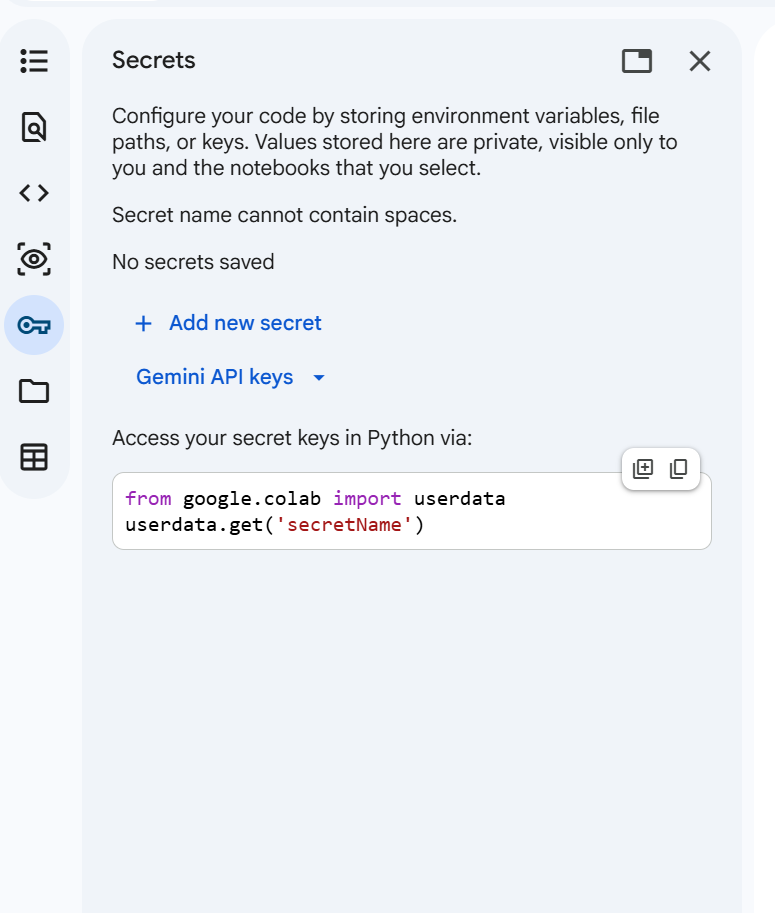

2. Then, click **+ Add new secret**. In the **Name** field, enter a name to identify the GitHub Personal Access Token, for example, **Gittoken**. In the **Value** field, paste the token. Once done, close the **Secrets** window. We will access this token programmatically later.

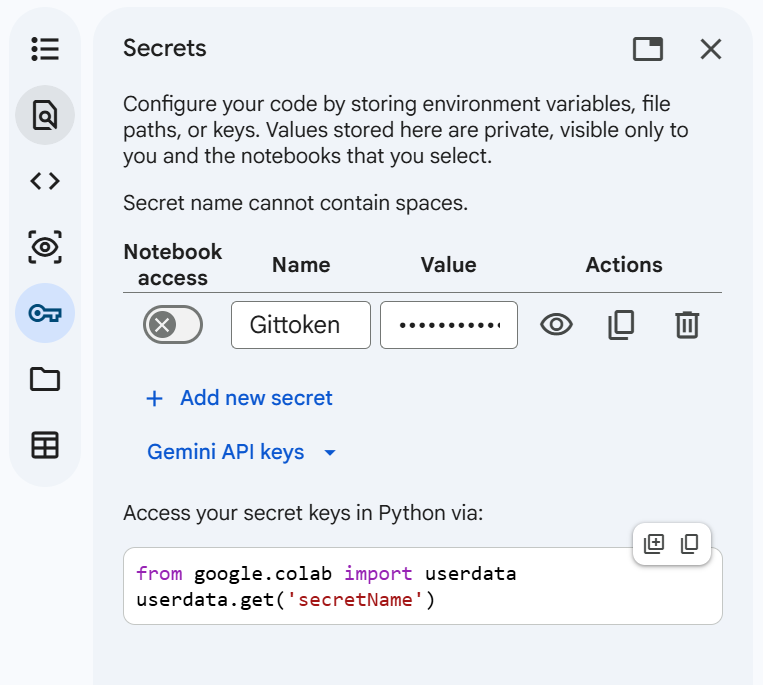

Once done, toggle the `Notebook access`

In [54]:
# Your GitHub Personal Access Token

from google.colab import userdata
GITHUB_TOKEN = userdata.get('git_token')  # Replace with the secret name. For example, Gittoken

# After executing this code, you may be prompted to grant access. Click **Grant Access** to continue.

The GitHub Personal Access Token is retrieved from Google Colab's secure secrets storage instead of being hardcoded. This keeps the token out of the notebook source code and out of version control.

1. **Define authentication and repository details:**
   - `GITHUB_TOKEN` stores the GitHub Personal Access Token for authentication.
   - `REPO_NAME` specifies the name of the new GitHub repository.

2. **Authenticate with GitHub:**
   - `g = Github(GITHUB_TOKEN)` creates a GitHub client using the token.
   - `user = g.get_user()` retrieves the authenticated user.

3. **Create the repository:**
   - `user.create_repo()` creates a new public repository on GitHub with an auto-generated README.

4. **Push files to the repository:**
   - `repo.create_file()` uploads each deployment file to the repository.
   - Backend files (`app.py`, `requirements.txt`, `Dockerfile`, model) go into the `backend/` folder.
   - Frontend files (`app.py`, `requirements.txt`, `Dockerfile`) go into the `frontend/` folder.
   - For the `.joblib` model file, which is binary, PyGithub handles the encoding automatically.

In [55]:
# Name for the repository
REPO_NAME = "aurora-stay-qna"

# Authenticate with GitHub
from github import Github
import os

g = Github(GITHUB_TOKEN)
user = g.get_user()

print(f"Authenticated as: {user.login}")


# ---------------------------------------------------------
# Get existing repository or create a new one
# ---------------------------------------------------------

try:
    # Check if repository already exists
    repo = user.get_repo(REPO_NAME)
    print(f"Repository already exists: {repo.html_url}")

except Exception:
    # Repository does not exist, so create it
    repo = user.create_repo(
        REPO_NAME,
        description="Aurora RAG",
        private=False,
        auto_init=True
    )

    print(f"Repository created successfully: {repo.html_url}")


# ---------------------------------------------------------
# Files to push
# ---------------------------------------------------------

files_to_push = {
    "backend/app.py": "backend_files/app.py",
    "backend/rag_utils.py": "backend_files/rag_utils.py",
    "backend/requirements.txt": "backend_files/requirements.txt",
    "backend/Dockerfile": "backend_files/Dockerfile",

    "frontend/app.py": "frontend_files/app.py",
    "frontend/requirements.txt": "frontend_files/requirements.txt",
    "frontend/Dockerfile": "frontend_files/Dockerfile",
}


# ---------------------------------------------------------
# Function to upload or update a file
# ---------------------------------------------------------

def upload_or_update_file(repo, repo_path, local_path):

    with open(local_path, "rb") as f:
        content = f.read()

    try:
        # Check if the file already exists
        existing_file = repo.get_contents(
            repo_path,
            ref="main"
        )

        # File exists -> update it
        repo.update_file(
            path=repo_path,
            message=f"Update {repo_path}",
            content=content,
            sha=existing_file.sha,
            branch="main"
        )

        print(f"Updated: {repo_path}")

    except Exception:
        # File does not exist -> create it
        repo.create_file(
            path=repo_path,
            message=f"Add {repo_path}",
            content=content,
            branch="main"
        )

        print(f"Uploaded: {repo_path}")


# ---------------------------------------------------------
# Upload / update individual files
# ---------------------------------------------------------

for repo_path, local_path in files_to_push.items():

    upload_or_update_file(
        repo,
        repo_path,
        local_path
    )

# ---------------------------------------------------------
# Upload / update FAISS index folder
# ---------------------------------------------------------

faiss_folder = "backend_files/faiss_index"

if os.path.exists(faiss_folder):

    for root, dirs, files in os.walk(faiss_folder):

        for file_name in files:

            # Full local path
            local_path = os.path.join(
                root,
                file_name
            )

            # Path relative to backend_files/
            relative_path = os.path.relpath(
                local_path,
                "backend_files"
            )

            # GitHub repository path
            repo_path = os.path.join(
                "backend",
                relative_path
            ).replace("\\", "/")

            upload_or_update_file(
                repo,
                repo_path,
                local_path
            )

else:
    print(
        f"Warning: FAISS folder not found: {faiss_folder}"
    )


print("\nAll files pushed successfully!")
print(f"Repository: {repo.html_url}")

Authenticated as: sudeepbhattad02-creator
Repository created successfully: https://github.com/sudeepbhattad02-creator/aurora-stay-qna
Uploaded: backend/app.py
Uploaded: backend/rag_utils.py
Uploaded: backend/requirements.txt
Uploaded: backend/Dockerfile
Uploaded: frontend/app.py
Uploaded: frontend/requirements.txt
Uploaded: frontend/Dockerfile
Uploaded: backend/faiss_index/index.pkl
Uploaded: backend/faiss_index/index.faiss

All files pushed successfully!
Repository: https://github.com/sudeepbhattad02-creator/aurora-stay-qna


Once all the files have been pushed, the next step is to add the secrets (OpenAI API Key and OpenAI Base URL) to GitHub Codespaces so that the backend can connect to OpenAI. For this, refer to the document titled **"Adding Secrets to GitHub Codespaces."**

**Note:** The link to your GitHub repository will be displayed as the output of the previous cell.

Then, refer to the document titled **"Deploying Frontend and Backend on GitHub Codespaces"** for the next steps to deploy the Streamlit application and see it in action.

# Deployment - Inference

Before executing the code cells below, ensure the following:

1. GitHub Codespaces is up and running.

2. Both the frontend and backend applications are running in GitHub Codespaces, and the ports are set to **Public**.

3. The forwarded URL of the backend is copied.(More details are provided in the document titled **"Deploying Frontend and Backend on GitHub Codespaces"**)

In [56]:
# Set the base URL for the deployed Flask API running in GitHub Codespaces
model_root_url = "https://didactic-space-fishstick-xrvp5596rrv7cp9q-7860.app.github.dev/"  # Replace with your Codespace forwarded URL for port 7860

Replace the URL above with the actual forwarded URL from your Codespace's Ports tab. It will look something like `https://organic-space-abcd1234-7860.app.github.dev`. Make sure there is no trailing slash at the end.

This URL is a tunnel that Codespaces creates to route external HTTP requests into your Codespace and to the Flask container running on port 7860.

In [57]:
model_chunks_url = model_root_url + "/v1/relevant_chunks"  # Endpoint for getting relevant chunks

Since our model predictions are served through the Flask endpoint we created, we need to call this endpoint to get the relevant chunks.

> ```@app.post('/v1/relevant_chunks')```

In [58]:
model_ans_chunks_url = model_root_url + "/v1/answer_with_relevant_chunks"  # Endpoint for getting the answer with relevant chunks

> ```@app.post('/v1/answer_with_relevant_chunks')```

The idea is to send a single request to the API and receive an immediate response. This is useful for real-time applications like recommendation systems and fraud detection.

* This data is sent as a JSON payload in a POST request to the model endpoint.
* The model processes the input features and returns a prediction as a JSON payload.

## Deployment - Inference (Relevant chunks)

**Guidelines**

- Enter a **hotel policy related question** in `query` to test the backend application.
- Set `k` to the number of policy chunks to retrieve. A value around **2 to 5** is a good starting point.
- You can try questions about **cancellations, refunds, pet policies, additional charges, room information, or accessibility**.
- Try different questions and `k` values to understand how they affect the retrieved information and the final response.

In [59]:
# Define the test payload with a sample hotel policy question and the number of chunks to retrieve
payload = {
    "query": "How much could AuroraStay charge if a guest smokes or vapes in a room?",  # Enter a hotel policy question to test the backend
    "k": 3,        # Enter the number of chunks to retrieve
}

In [60]:
# Sending a POST request to the model endpoint with the test payload
response = requests.post(model_chunks_url, json=payload)

In [61]:
# Check the HTTP status of the response
response

<Response [200]>

- The `<Response [200]>` you see is an HTTP status code.
- It indicates that your request was successful, and the server was able to process it without any problems.

In [62]:
# Print the full JSON response containing the retrieved chunks
print(response.json())

{'k': 3, 'query': 'How much could AuroraStay charge if a guest smokes or vapes in a room?', 'relevant_chunks': ["Content:\n| Late checkout                 | Property-specific; may be a flat fee or additional night      | Guest receives an approved departure extension.                                       | Confirm the new departure time and exact fee before approval.                                                                     |\n| Smoking or vaping remediation | Up to $250 baseline, subject to evidence and local law        | Credible evidence shows smoking or vaping in a prohibited guest room or indoor area.  | Explain the rule, evidence category, charge basis, and dispute channel. Do not charge based on odor alone when facts are unclear. |\n| Lost key or device            | Reasonable replacement cost when stated in the property terms | A guest does not return a physical key, parking device, or other property asset.      | State the item, replacement basis, and how the guest 

- The JSON output contains the original query, the value of k, and a list of the top-k retrieved chunks.
- Each chunk includes the text content and metadata showing which source document it came from.
- This confirms the retrieval endpoint is working correctly on the deployed backend.

## Deployment - Inference (Answer with relevant chunks)

**Guidelines**

- Enter a **hotel policy related question** in `query` to test the answer endpoint.
- Set `k` to the number of policy chunks to retrieve. A value around **2 to 5** is a good starting point.
- The `model_name` specifies the LLM used to generate the answer.
- Set `temperature` to a low value, such as **0 to 0.2**, for more consistent responses.
- Set `top_p` around **0.9 to 1** for consistent token selection.
- Set `max_tokens` based on the expected answer length. **256 to 512** is a reasonable starting range.
- The values can be adjusted to understand how the retrieval and generation settings affect the response.

In [63]:
# Define the test payload with the query and model parameters for the answer endpoint
payload = {
    "query": "How much could AuroraStay charge if a guest smokes or vapes in a room?",          # Enter a hotel policy question to test the answer endpoint
    "k": 3,                 # Enter the number of chunks to retrieve
    "model_name": "gpt-4o-mini", # Enter the LLM model name
    "temperature": 0.0,       # Enter a low value for more consistent responses
    "top_p": 1.0,             # Enter a value close to 1 for balanced token selection
    "max_tokens": 512         # Enter a suitable limit based on the expected answer length
}

**Note:** The below code snippet may take some time to execute, typically between 1 to 3 minutes.

In [67]:
# Sending a POST request to the model endpoint with the test payload
response = requests.post(model_ans_chunks_url, json=payload)

In [68]:
# Check the HTTP status of the response
response

<Response [200]>

- The `<Response [200]>` you see is an HTTP status code.
- It indicates that your request was successful, and the server was able to process it without any problems.

In [69]:
# Print the full JSON response containing the answer and supporting chunks
print(response.json())

{'answer': "AuroraStay could charge up to a $250 baseline fee if credible evidence shows that smoking or vaping occurred in a prohibited guest room or indoor area. However, this amount is subject to local law and may vary based on the specific property’s policies. It's important to note that charges should not be based solely on odor when the facts are unclear.", 'k': 3, 'max_tokens': 512, 'model_name': 'gpt-4o-mini', 'query': 'How much could AuroraStay charge if a guest smokes or vapes in a room?', 'relevant_chunks': ["Content:\n| Late checkout                 | Property-specific; may be a flat fee or additional night      | Guest receives an approved departure extension.                                       | Confirm the new departure time and exact fee before approval.                                                                     |\n| Smoking or vaping remediation | Up to $250 baseline, subject to evidence and local law        | Credible evidence shows smoking or vaping in a 

- The JSON response now includes both the generated answer and the relevant chunks that were used to produce it.
- This is the same payload the Streamlit frontend receives when the user selects "Answer + Relevant Chunks" mode.
- Having both the answer and its supporting evidence in a single response makes it easy for hotel staff to verify the information before sharing it with guests.

**IMPORTANT:** Once the previous cell has been executed and the application is no longer required, please refer to the document titled **"Deleting Codespace"** to delete the Codespace, as it may continue to consume resources.

# Business Insights and Recommendations

--

### **1. Key Business Insights**

* **Successful Feasibility Demonstration (POC):** The system successfully achieved high **Faithfulness** and **Answer Relevancy** across both the evaluation and unseen test datasets (consistently scoring above 0.85 to 1.0 on these metrics). This proves that the core RAG architecture can produce high-quality, hallucination-free responses using only your hotel policies.
* **Bottlenecks in Retrieval completeness (Contextual Recall):** Some test queries (such as OTA booking cancellations or member discount policies) had relatively low *Contextual Recall* and *Contextual Precision* scores. This indicates that while the LLM is faithful when text is present, our retriever setup occasionally fails to fetch the comprehensive, cross-policy details required for highly specific queries.
* **Operational Efficiency Gains (The 50% Threshold):** Over 50% of the tested queries automatically routed to **AUTO ANSWER** (with composite scores > 0.75), meeting your primary technical success criteria. This represents a massive opportunity to deflect simple and repetitive workloads away from manual policy search, preserving human effort for the remaining ~45% of queries requiring **ASSISTED REVIEW** or **MANUAL LOOKUP**.

### **2. Actionable Strategic Recommendations**

#### **A. Short-Term Pipeline Optimizations**
* **Implement Query Rewriting / Expansion:** Enhance the user queries before they hit the vector database. For example, rewriting short, conversational guest queries into more precise terms (e.g., mapping "cancel for free" to "cancellation policy deadlines") will dramatically improve Contextual Precision and Recall.
* **Optimize Chunk Size & Multi-Vector Retrieval:** Some policies are nested inside wide tables (e.g., property-specific grids). Expanding the retrieval strategy to pull in parent-child headers alongside tables ensures that the LLM receives the full context of which property and fee rules apply.

#### **B. Medium-Term Operational Integration**
* **Build a Dual-Lane Agent UI:** Integrate the calculated composite score directly into the staff's workflow. For **AUTO ANSWER** status, allow immediate copying of the generated draft. For **ASSISTED REVIEW** status, show the draft but highlight the retrieved source chunks in an interactive pane so agents can manually verify the facts within seconds rather than minutes.
* **Implement a Continuous Feedback Loop:** Provide a "thumbs up / thumbs down" mechanism in the UI. Save the queries that result in downvotes (or score low during production runs) back to a dedicated dataset. Use this to refine chunking strategies and systematically retrain embeddings over time.

#### **C. Long-Term Governance and Scalability**
* **Policy Authoring Standards:** As AuroraStay adds 3 to 4 properties annually, require newly drafted policy PDFs to follow structured, machine-readable formats (clear heading Hierarchies, explicit columns in tables, consistent terminology). This prevents "garbage in, garbage out" and keeps RAG retrieval highly performant without custom manual data wrangling.
* **Transition to Hybrid Search:** Combine the fine-tuned dense embeddings with lexical BM25 (keyword) search. This ensures that exact matches on specific property names (e.g., "ASH-BOS Harbor" vs "ASH-SEA Pike") and numeric values (e.g., "24 hours", "$250") are retrieved with near-perfect reliability.